# NAVTTC Week 7 - Task 64
## CNN on the CIFAR-10 Dataset

## Objective
Train a CNN on **CIFAR-10**, a standard dataset of 32×32 color images belonging to 10 classes.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.random.set_seed(42)
np.random.seed(42)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

## Load and Normalize CIFAR-10
`tf.keras.datasets.cifar10.load_data()` downloads the dataset on first use if it is not already cached. Pixel values are scaled to the range 0–1.

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
y_train = y_train.ravel()
y_test = y_test.ravel()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1110s 7us/step
Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)


## Display Sample Images

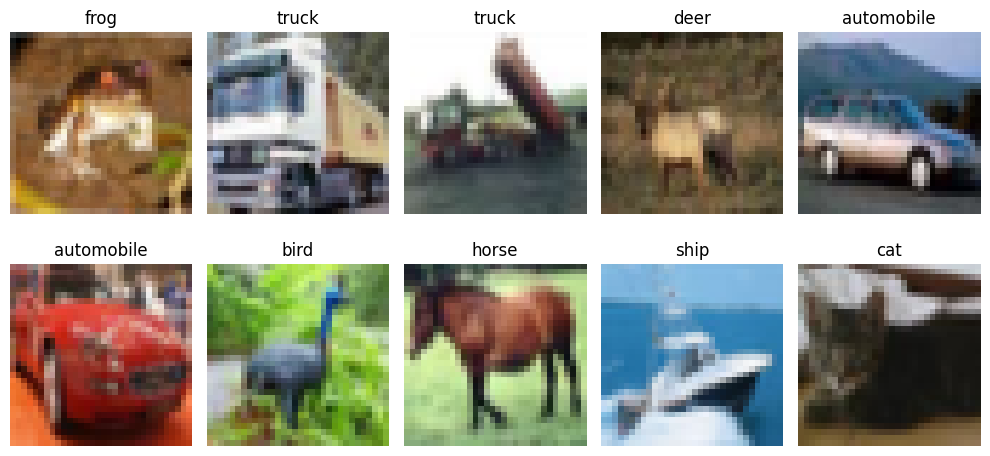

In [3]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Define the CNN Architecture

In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

## Train the Model
Ten epochs are used as a manageable classroom demonstration. More training and augmentation can improve performance.

In [5]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    verbose=1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 217s 302ms/step - accuracy: 0.3568 - loss: 1.7485 - val_accuracy: 0.4982 - val_loss: 1.3750
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 262s 303ms/step - accuracy: 0.5175 - loss: 1.3410 - val_accuracy: 0.6148 - val_loss: 1.0905
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 212s 301ms/step - accuracy: 0.5840 - loss: 1.1621 - val_accuracy: 0.6726 - val_loss: 0.9367
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 209s 298ms/step - accuracy: 0.6266 - loss: 1.0574 - val_accuracy: 0.6822 - val_loss: 0.8952
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 211s 299ms/step - accuracy: 0.6531 - loss: 0.9878 - val_accuracy: 0.6952 - val_loss: 0.8681
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 210s 298ms/step - accuracy: 0.6775 - loss: 0.9260 - val_accuracy: 0.7322 - val_loss: 0.7981
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 270s 310ms/step - accuracy: 0.6940 - loss: 0.8731 - val_accuracy: 0.7252 - val_loss: 0.7867
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 257s 302ms/step - accuracy: 0.7072 -

## Evaluate on the Test Set

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss: 0.7271
Test accuracy: 0.7469


## Plot Training History

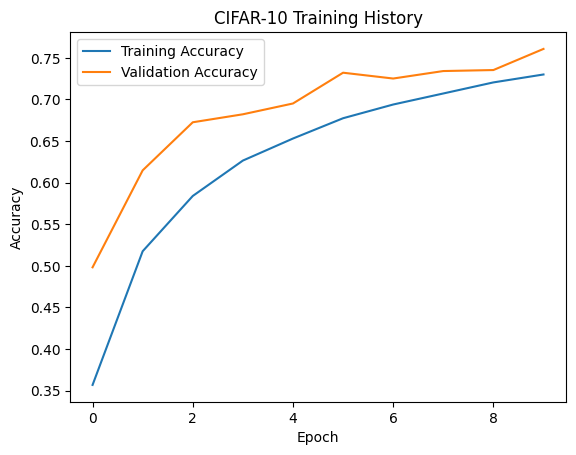

In [7]:
plt.figure()
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CIFAR-10 Training History")
plt.legend()
plt.show()

## Predict Test Images

In [8]:
probabilities = model.predict(X_test[:10], verbose=0)
predictions = probabilities.argmax(axis=1)

for i, (pred, actual) in enumerate(zip(predictions, y_test[:10]), start=1):
    print(f"Sample {i}: predicted={class_names[pred]}, actual={class_names[actual]}")

Sample 1: predicted=cat, actual=cat
Sample 2: predicted=ship, actual=ship
Sample 3: predicted=ship, actual=ship
Sample 4: predicted=ship, actual=airplane
Sample 5: predicted=frog, actual=frog
Sample 6: predicted=frog, actual=frog
Sample 7: predicted=automobile, actual=automobile
Sample 8: predicted=deer, actual=frog
Sample 9: predicted=deer, actual=cat
Sample 10: predicted=automobile, actual=automobile


## Conclusion
This task implements a complete CIFAR-10 workflow: loading, normalization, visualization, CNN design, training, evaluation, and prediction.